In [1]:
import numpy as np

distances = np.array([1.0, 2.0, 3.0])  # km: trips A, B, C
durations = np.array([4.0, 9.0, 12.0])  # minutes

def mean_squared_loss(w):
    errors = w * distances - durations
    return np.mean(errors ** 2)

def loss_slope(w):
    errors = w * distances - durations
    return 2 * np.mean(errors * distances)   # the 2 comes from the derivative of the square

print(mean_squared_loss(0), loss_slope(0))
print(mean_squared_loss(58 / 14), loss_slope(58 / 14))

80.33333333333333 -38.666666666666664
0.23809523809523836 5.329070518200751e-15


store the distances and durations of the 3 trips
loss(w): errors = w × distances − durations; mean of the squares
slope(w): same errors; 2 × mean(errors × distances)
print the loss and the slope at w = 0
print the loss and the slope at w = 58/14, the bottom of the valley

In [2]:
def gradient_descent(learning_rate, number_of_steps, w_start=0.0):
    w = w_start
    losses = [float(mean_squared_loss(w))]
    for _ in range(number_of_steps):
        w = w - learning_rate * loss_slope(w)
        losses.append(float(mean_squared_loss(w)))
    return w, losses

# Check: a single step of 0.05 must give back the calculation on the page
w_after_one_step, losses = gradient_descent(learning_rate=0.05, number_of_steps=1)
print(round(w_after_one_step, 2), [round(loss, 1) for loss in losses])

# 20 steps for each of the three learning rates
for learning_rate in (0.01, 0.08, 0.23):
    w_final, losses = gradient_descent(learning_rate, number_of_steps=20)
    print(learning_rate, round(w_final, 2), round(losses[-1], 2))

1.93 [80.3, 23.0]
0.01 3.56 1.83
0.08 4.14 0.24
0.23 -59.84 19102.91


start from w = 0 and record the loss
repeat N times: w ← w − learning rate × slope(w), record the new loss
return the last w and the list of losses
check: 1 step of 0.05 → the number on the page
then 20 steps with 0.01, 0.08 and 0.23: print the final w and the final loss

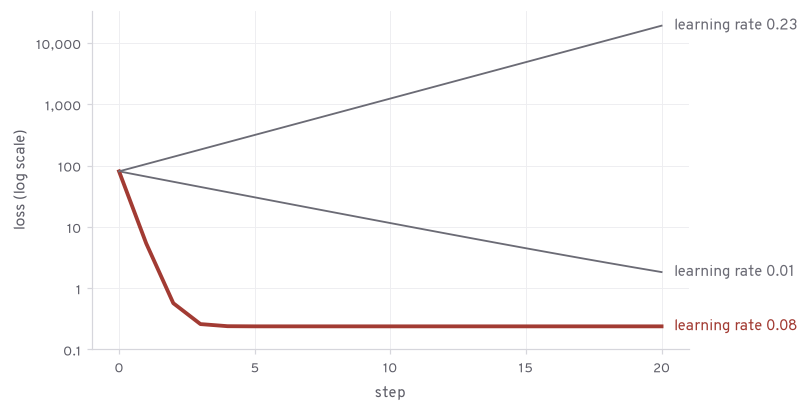

In [3]:
import sys
sys.path.insert(0, "../../../style")
from charte import charger_charte, sauver_clair_et_sombre  # shared style: fonts, colours, light and dark export
import matplotlib.pyplot as plt

charger_charte()

losses_by_learning_rate = {rate: gradient_descent(rate, number_of_steps=20)[1] for rate in (0.01, 0.08, 0.23)}

def draw(colours):
    figure, axis = plt.subplots(figsize=(7, 4))
    colour_by_rate = {0.01: colours["trait"], 0.08: colours["accent"], 0.23: colours["trait"]}
    for rate, losses in losses_by_learning_rate.items():
        colour = colour_by_rate[rate]
        axis.plot(losses, color=colour, linewidth=2.5 if rate == 0.08 else 1.2)
        axis.annotate(f"learning rate {rate}", (20, losses[-1]), xytext=(8, 0),
                      textcoords="offset points", va="center", color=colour)
    axis.set_yscale("log")  # 0.24 and 19,103 on one axis: only a log scale shows all three curves
    axis.set_yticks([0.1, 1, 10, 100, 1000, 10000], ["0.1", "1", "10", "100", "1,000", "10,000"])
    axis.minorticks_off()
    axis.set_xticks(range(0, 21, 5))
    axis.set_xlabel("step")
    axis.set_ylabel("loss (log scale)")
    return figure

sauver_clair_et_sombre(draw, "loss_by_learning_rate")

load the shared style (fonts, colours)
for each learning rate (0.01, 0.08, 0.23): keep the 21 losses of the descent
draw one curve per rate, each labelled at the end of its line
vertical axis on a log scale
save two versions: _clair.png (light) and _sombre.png (dark)